# Counterfactual Finder (v2) — Weda Bay

This notebook finds **counterfactual locations** for a mining site: places within 50 km that *looked like the mine area before mining*, but are not affected by it. They act as the "control group" when we measure the mine's impact on water quality and forest.

It is set up for one site, **Weda Bay Nickel / IWIP** (0.4711° N, 127.9440° E). The section *Running your own site* at the end explains how to change it.

### How it works

Every pixel on Earth has a **64-number fingerprint** from Google's AlphaEarth Foundations embedding (`GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL`). Two pixels with similar fingerprints look and behave similarly across many satellite sensors. We use the **2018** fingerprints (before most of the impact we want to measure).

For each site we run two pipelines, **LAND** and **COASTAL**:

| Step | What happens |
|---|---|
| 1. Treatment area | 10 km buffer around the site (land part or water part). |
| 2. Search area | 10–50 km ring. Land: same ecoregion and watershed, intact forest only. Coastal: water only. Other mines' 10 km buffers are excluded; placebo sites stay eligible. |
| 3. Cluster | K-means (k = 10) splits the treatment area into 10 "landscape types". |
| 4. Reference points | 30 random points spread over the clusters in proportion to their size. |
| 5. Similarity search | For each reference point, find the 10 most similar pixels in the search area (cosine similarity, a dot product of unit-length fingerprints). |
| 6. Export | 30 × 10 = **300 counterfactual points** per pipeline, exported as CSV to Google Drive. |

### Before you start
* You need a Google account with **Earth Engine access** and a Google Cloud project registered for Earth Engine (set `GEE_PROJECT` below). Step-by-step instructions: [`docs/earth_engine.md`](../docs/earth_engine.md).
* Works in **Google Colab** or a local Jupyter install.
* **Demo mode** (`USE_DEMO_RESULTS = True` in Section 2, the default): no Earth Engine export is submitted; sections C and D load the pre-computed Weda Bay results from `data/counterfactual_demo/`. Earth Engine access is still needed for the geometry, clustering and map steps.
* The exclusion zones (10 km buffers of the seven nickel mining sites in the study) are read from `data/mine_buffers_10km.geojson`. In Colab the setup cell clones the repository, so the file is available. Set `EXCLUSION_GEOJSON = None` to search without exclusions.

### What are AlphaEarth Foundations (AEF) embeddings?

**AEF** is a global geospatial foundation model from Google DeepMind (Brown et al., 2025). For every **10 m pixel** and every year since **2017**, it produces an **embedding**: 64 abstract numbers (bands `A00`–`A63`) that summarise what that place looks like and how it behaves over the year.

* **Inputs:** Sentinel-1 radar, Sentinel-2 optical and Landsat optical/thermal time series. The model treats the year's acquisitions like a continuous "video", so cloudy, gappy time series collapse into one consistent annual value that also captures seasonality (phenology).
* **Training targets:** richer data than the inputs, including GEDI LiDAR (canopy structure), ERA5 (climate), GRACE (gravity) and elevation models (topography). The embedding therefore also encodes structure, climate and terrain.
* **Mental model:** think of AEF as a *virtual satellite* that has learnt a PCA across all those time series. Like PCA it compresses many dimensions into a few. Unlike PCA, the 64 axes are not chosen to maximise variance; they are shaped by what the model needed to predict LiDAR, climate and topography. A single band has no physical meaning; **always use all 64 together**.
* **Similarity search:** every embedding has unit length, so the dot product of two pixels' embeddings is their **cosine similarity**. Close to 1 means very similar places; lower means less similar. This is how we find counterfactuals.
* **Coverage:** land surfaces plus shallow, coastal and inland water. Deeper open sea has **no data**, so coastal counterfactuals can only come from near-shore water.

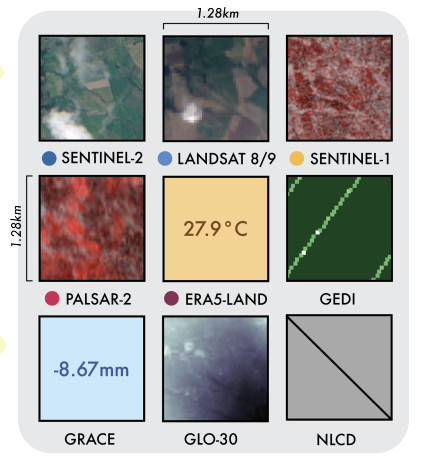

*Data sources behind AEF (Brown et al., 2025): satellite inputs (Sentinel-2, Landsat, Sentinel-1, PALSAR-2) and training targets such as ERA5-Land climate, GEDI LiDAR, GRACE and GLO-30 elevation, each shown for one 1.28 km tile.*

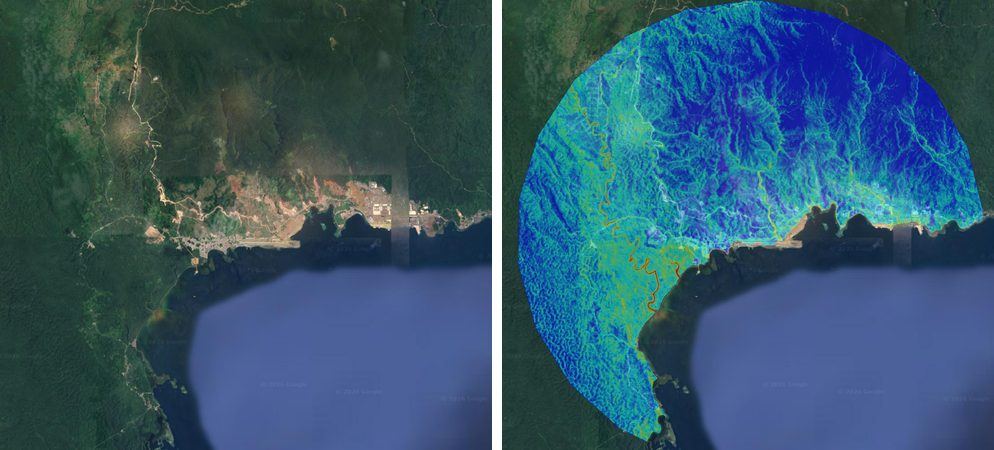

*Similarity search at Weda Bay. Left: satellite image. Right: cosine similarity of every pixel to one reference pixel on the river (red = most similar, blue = least similar). The river network lights up although nothing told the model what a river is. This notebook uses the same operation to find counterfactuals. Source: Google Earth Engine, AlphaEarth Satellite Embeddings v1.*

Dataset in Earth Engine: `GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL`.

## 1. Setup

In [ ]:
# Google Colab: fetch the repository so that data/ is available (does nothing when run locally)
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.isdir("data"):
    subprocess.run(["git", "clone", "https://github.com/Hauzero/Bridge-SpatialSustainableFinance.git"], check=True)
    os.chdir("Bridge-SpatialSustainableFinance/notebooks")


In [1]:
%pip install -q earthengine-api folium

Note: you may need to restart the kernel to use updated packages.


In [2]:
import ee
import json
import math
import os
import time

import pandas as pd
import matplotlib.pyplot as plt

GEE_PROJECT = "your-gee-cloud-project"   # <-- change to your own Earth Engine Cloud project

try:
    ee.Initialize(project=GEE_PROJECT)
except Exception:      # first run: log in once, then initialise
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT)
print("Earth Engine initialised with project:", GEE_PROJECT)

Earth Engine initialised with project: your-gee-cloud-project


## 2. Parameters

The site is set here. To run your own site later, change `SITE_NAME`, `SITE_LAT` and `SITE_LON` (decimal degrees, WGS84). Leave the other values as they are to stay consistent with v2.

In [3]:
# ── Site ──────────────────────────────────────────────────────────
SITE_NAME = "Weda_Bay_Nickel_IWIP"
SITE_LAT  = 0.47114758
SITE_LON  = 127.9439985

# ── Method settings (v2 defaults) ─────────────────────────────────
YEAR          = 2018       # AlphaEarth embedding year (pre-impact baseline)
MINE_BUF_M    = 10_000     # treatment buffer radius (m)
SEARCH_BUF_M  = 50_000     # search radius (m)
N_CLUSTERS    = 10         # K-means clusters in the treatment area
TOTAL_SAMPLES = 30         # reference points per pipeline
TOP_K         = 10         # most similar pixels kept per reference point
SEARCH_PIXELS = 50_000     # random search-area pixels scored per reference point
LAND_SCALE    = 30         # m
COASTAL_SCALE = 300        # m (matches ocean-colour products)
GD_FOLDER     = "EE_Counterfactuals"   # Google Drive export folder

# ── Exclusion zones: 10 km buffers of all sites; only IsMine = 1 is excluded ──
# Set to None to search without exclusions.
DATA = "../data" if os.path.isdir("../data") else "data"      # notebooks/ -> ../data, repository root -> data
EXCLUSION_GEOJSON = os.path.join(DATA, "mine_buffers_10km.geojson")

# ── Demo ──────────────────────────────────────────────────────────
# True: skip waiting for the Earth Engine exports and load pre-computed results
# ({SITE_NAME}_LAND/COASTAL_counterfactuals.csv) from DEMO_RESULTS_DIR instead.
USE_DEMO_RESULTS = True
DEMO_RESULTS_DIR = os.path.join(DATA, "counterfactual_demo")   # folder with the demo CSVs

## 3. Datasets

* **AlphaEarth embeddings**: 64-band annual fingerprints at 10 m.
* **Shorelines** (sat-io): separates land from water.
* **Hansen Global Forest Change**: keeps land counterfactuals in forest that was intact in 2000 and not lost 2017–2024.
* **RESOLVE Ecoregions** and **HydroSHEDS level-8 basins**: land counterfactuals must share the site's ecoregion and watershed.
* **Exclusion zones**: counterfactuals may never fall inside another **mine's** 10 km buffer (`data/mine_buffers_10km.geojson`).

In [4]:
embeddings_col = ee.ImageCollection("GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL")

shoreline_all = (ee.FeatureCollection("projects/sat-io/open-datasets/shoreline/mainlands")
                 .merge(ee.FeatureCollection("projects/sat-io/open-datasets/shoreline/big_islands"))
                 .merge(ee.FeatureCollection("projects/sat-io/open-datasets/shoreline/small_islands")))

hansen      = ee.Image("UMD/hansen/global_forest_change_2025_v1_13")
forest_2000 = hansen.select("treecover2000").gte(30)
loss_recent = hansen.select("lossyear").gte(17).And(hansen.select("lossyear").lte(24))

ecoregions_fc = ee.FeatureCollection("RESOLVE/ECOREGIONS/2017")
watersheds_fc = ee.FeatureCollection("WWF/HydroSHEDS/v1/Basins/hybas_8")

if EXCLUSION_GEOJSON and os.path.exists(EXCLUSION_GEOJSON):
    with open(EXCLUSION_GEOJSON, "r") as f:
        gj = json.load(f)
    # Exclude mines only (IsMine = 1); placebo sites stay eligible as counterfactuals
    mines = [f for f in gj.get("features", [])
             if int(float(f["properties"].get("IsMine") or 0)) == 1]
    for feat in mines:
        feat["properties"] = {}   # other attributes break the GEE upload
        feat.pop("id", None)
    exclusion_zones    = ee.FeatureCollection(mines)
    exclusion_geometry = exclusion_zones.geometry()
    exclusion_mask     = ee.Image.constant(1).paint(exclusion_zones, 0).selfMask()
    print(f"Excluding {len(mines)} mine buffers "
          f"({len(gj['features']) - len(mines)} placebo buffers stay eligible)")
else:
    exclusion_zones    = None
    exclusion_geometry = None
    exclusion_mask     = ee.Image.constant(1)
    print("WARNING: no exclusion file found, searching without exclusion zones")


def remove_exclusions(geom):
    return geom.difference(exclusion_geometry, 1) if exclusion_geometry is not None else geom

Excluding 7 mine buffers (7 placebo buffers stay eligible)


## 4. Helper functions

Run this cell once. Each function is one building block of the method.

In [5]:
def make_mosaic(region, year=YEAR):
    """Annual AlphaEarth embedding mosaic clipped to region."""
    return (embeddings_col
            .filterDate(ee.Date.fromYMD(year, 1, 1), ee.Date.fromYMD(year, 12, 31))
            .filterBounds(region)
            .mosaic()
            .clip(region))


def shore_distance(shoreline_fc, clip_region):
    """Distance to shoreline, scaled to 0-1 (0 = at the shore, 1 = 5 km or more offshore)."""
    shore = ee.Image().toByte().paint(shoreline_fc, 1).clip(clip_region)
    return (shore.Not().fastDistanceTransform().sqrt()
            .multiply(ee.Image.pixelArea().sqrt())
            .divide(5000).clamp(0, 1).rename("distance_to_shore"))


def count_pixels(img, region, scale):
    n = img.select(0).reduceRegion(reducer=ee.Reducer.count(), geometry=region,
                                   scale=scale, maxPixels=1e9, tileScale=4).values().get(0)
    return ee.Number(n).getInfo()


def adaptive_counts(n_pixels):
    """Fewer clusters / reference points when the treatment area is tiny."""
    n_clusters = min(N_CLUSTERS, max(2, n_pixels // 50))
    total_samples = max(min(TOTAL_SAMPLES, n_pixels // 5), n_clusters)
    return n_clusters, total_samples


def cluster_image(img, region, scale, n_clusters):
    """K-means on the treatment area. Returns a 'clusters' band numbered 1..n."""
    training = img.sample(region=region, scale=scale, numPixels=5000, seed=42, tileScale=4)
    clusterer = ee.Clusterer.wekaKMeans(nClusters=n_clusters, seed=42).train(training)
    return img.cluster(clusterer, "clusters").select("clusters").add(1)


def cluster_histogram(cluster_img, region, scale):
    return (cluster_img.reduceRegion(reducer=ee.Reducer.frequencyHistogram(), geometry=region,
                                     scale=scale, maxPixels=1e9, tileScale=4)
            .get("clusters").getInfo())


def proportional_allocation(hist_dict, total):
    """Split `total` reference points over clusters by pixel share, at least 1 per cluster."""
    total_px = sum(hist_dict.values())
    alloc = {}
    for cid_str, px in hist_dict.items():
        raw = px / total_px * total
        alloc[int(cid_str)] = {"n": max(1, math.floor(raw)), "frac": raw % 1}
    remainder = total - sum(v["n"] for v in alloc.values())
    if remainder > 0:
        ranked = sorted(alloc, key=lambda c: alloc[c]["frac"], reverse=True)
        for i in range(remainder):
            alloc[ranked[i % len(ranked)]]["n"] += 1
    elif remainder < 0:
        ranked = sorted(alloc, key=lambda c: alloc[c]["frac"])
        for i in range(-remainder):
            c = ranked[i % len(ranked)]
            alloc[c]["n"] = max(1, alloc[c]["n"] - 1)
    return {c: v["n"] for c, v in alloc.items()}


def pick_reference_points(cluster_img, region, scale, samples_per_cluster):
    """Stratified random sample: exactly the allocated number of points from each cluster."""
    class_values = list(samples_per_cluster)
    ref_fc = cluster_img.stratifiedSample(
        numPoints=0, classBand="clusters", region=region, scale=scale,
        classValues=class_values,
        classPoints=[samples_per_cluster[c] for c in class_values],
        geometries=True, seed=42, tileScale=4)
    per_cluster = ref_fc.aggregate_histogram("clusters").getInfo()
    print("Reference points per cluster:", {int(k): v for k, v in sorted(per_cluster.items(), key=lambda kv: int(kv[0]))})
    print(f"-> {sum(per_cluster.values())} reference points")
    return ref_fc


def similarity_search(ref_mosaic, search_mosaic, search_region, ref_fc, scale, site_lat, site_lon):
    """For every reference point: dot product of its embedding with every search pixel,
    score SEARCH_PIXELS random pixels, keep the TOP_K best. Runs fully on GEE."""
    band_names = ref_mosaic.bandNames()
    refs = ref_mosaic.sampleRegions(collection=ref_fc, scale=scale, geometries=True)
    ref_list = refs.toList(refs.size())

    def top_similar(i):
        i = ee.Number(i)
        ref = ee.Feature(ref_list.get(i))
        ref_vec = ee.Image.constant(ref.toArray(band_names)).arrayFlatten([band_names])
        sim = ref_vec.multiply(search_mosaic).reduce("sum")
        cands = sim.addBands(ee.Image.pixelLonLat()).sample(
            region=search_region, scale=scale, numPixels=SEARCH_PIXELS,
            seed=i.add(1000), geometries=True, tileScale=4)
        return cands.sort("sum", False).limit(TOP_K).map(lambda pt: ee.Feature(pt).set({
            "source_cluster": ref.get("clusters"),
            "ref_index": i,
            "similarity": ee.Feature(pt).get("sum"),
            "longitude": ee.Feature(pt).geometry().coordinates().get(0),
            "latitude": ee.Feature(pt).geometry().coordinates().get(1),
            "site_lat": site_lat,
            "site_lon": site_lon,
        }))

    return ee.FeatureCollection(ee.List.sequence(0, refs.size().subtract(1)).map(top_similar)).flatten()


def export_to_drive(fc, description):
    task = ee.batch.Export.table.toDrive(
        collection=fc, description=description, folder=GD_FOLDER,
        fileNamePrefix=description, fileFormat="CSV",
        selectors=["latitude", "longitude", "similarity", "source_cluster",
                   "ref_index", "site_lat", "site_lon"])
    task.start()
    print(f"Export task submitted: {description}  ->  Drive/{GD_FOLDER}/")
    return task


AEF_VIS = {"bands": ["A01", "A16", "A09"], "min": -0.3, "max": 0.3}


def show_map(layers, zoom=9):
    """layers: list of (ee_object, vis_params, name). Images become Earth Engine tile
    layers; FeatureCollections (e.g. the reference points) are drawn as markers."""
    import folium
    m = folium.Map(location=[SITE_LAT, SITE_LON], zoom_start=zoom, tiles=None)
    folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Esri", name="Satellite").add_to(m)

    for obj, vis, name in layers:
        if isinstance(obj, ee.FeatureCollection):
            group = folium.FeatureGroup(name=name)
            for f in obj.getInfo()["features"]:
                geom = f["geometry"]
                if geom["type"] == "Point":
                    lon, lat = geom["coordinates"]
                    folium.CircleMarker(
                        [lat, lon], radius=4, color=vis.get("color", "red"), fill=True,
                        fill_opacity=0.9, tooltip=f"cluster {f['properties'].get('clusters')}",
                    ).add_to(group)
                else:
                    folium.GeoJson(geom).add_to(group)
            group.add_to(m)
        else:
            url = ee.Image(obj).getMapId(vis)["tile_fetcher"].url_format
            folium.TileLayer(tiles=url, attr="Google Earth Engine", name=name,
                             overlay=True, control=True).add_to(m)

    folium.Marker([SITE_LAT, SITE_LON], tooltip=SITE_NAME).add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    return m

## 5. Site geometry

The 10 km **treatment buffer** and the 50 km **search circle** are shared by both pipelines.

In [6]:
mine_pt       = ee.Geometry.Point([SITE_LON, SITE_LAT])
mine_buffer   = mine_pt.buffer(MINE_BUF_M)
search_circle = mine_pt.buffer(SEARCH_BUF_M)
print(f"{SITE_NAME}: ({SITE_LAT}, {SITE_LON})")

# Map layer: the other mines' buffers (this site's own buffer is drawn separately)
other_mines_layer = ([(ee.Image().paint(exclusion_zones.filter(ee.Filter.bounds(mine_pt).Not()), 1, 2),
                       {"palette": ["red"]}, "Other mines' 10 km buffers (excluded)")]
                     if exclusion_zones is not None else [])

Weda_Bay_Nickel_IWIP: (0.47114758, 127.9439985)


---
# A. LAND pipeline (30 m)

### A1. Search area: same ecoregion and watershed

Land counterfactuals must sit in the same **ecoregion** as the site and in a **watershed** that touches the treatment buffer, so that climate, geology and drainage are comparable. If the site is on a small island without these polygons, the script falls back to whatever is available.

In [7]:
eco_hits   = ecoregions_fc.filterBounds(mine_buffer)
wshed_hits = watersheds_fc.filterBounds(mine_buffer)
eco_count, wshed_count = eco_hits.size().getInfo(), wshed_hits.size().getInfo()

if eco_count == 0 and wshed_count == 0:
    print("No ecoregion or watershed found: using the 50 km circle")
    geo_bounds = search_circle
elif eco_count == 0:
    print("No ecoregion found: using watersheds ∩ 50 km")
    geo_bounds = wshed_hits.geometry().intersection(search_circle)
elif wshed_count == 0:
    print("No watershed found: using ecoregion ∩ 50 km")
    geo_bounds = eco_hits.first().geometry().intersection(search_circle)
else:
    print("Ecoregion:", eco_hits.first().get("ECO_NAME").getInfo())
    print("Watersheds touching the buffer:", wshed_count)
    geo_bounds = (eco_hits.first().geometry()
                  .intersection(wshed_hits.geometry()).intersection(search_circle))

land_search = remove_exclusions(geo_bounds.difference(mine_buffer))

land_area = land_search.area(100).getInfo()
land_ok = land_area >= 1e5
print(f"Land search area: {land_area / 1e6:.1f} km²" if land_ok
      else "Negligible land in the search area: skip the LAND pipeline")

Ecoregion: Halmahera rain forests
Watersheds touching the buffer: 3
Land search area: 2046.8 km²


### A2. Intact-forest mask, embeddings and pixel count

Search pixels must be forest in 2000 (≥ 30 % tree cover) and not lost between 2017 and 2024, so counterfactuals are not themselves disturbed. The pixel count decides how many clusters and reference points we can afford (10 and 30 for any normal-sized site).

In [8]:
if land_ok:
    keep_mask = (ee.Image(1)
                 .updateMask(ee.Image().toByte().paint(land_search, 1))
                 .where(forest_2000.Not().Or(loss_recent), 0)
                 .gt(0)
                 .updateMask(exclusion_mask))

    land_mosaic = make_mosaic(geo_bounds)
    land_treat  = land_mosaic.clip(mine_buffer)

    land_px = count_pixels(land_treat, mine_buffer, LAND_SCALE)
    land_ok = land_px >= 10
    land_n_clusters, land_n_refs = adaptive_counts(land_px)
    print(f"Pixels in treatment area: {land_px:,}")
    print(f"-> {land_n_clusters} clusters, {land_n_refs} reference points, "
          f"{land_n_refs * TOP_K} counterfactuals")

Pixels in treatment area: 210,763
-> 10 clusters, 30 reference points, 300 counterfactuals


### A3. K-means clusters and reference-point allocation

The treatment area is split into landscape types; reference points are allocated in proportion to each type's area (minimum 1 each), so the counterfactual set mirrors the composition of the mine area.

In [9]:
if land_ok:
    land_clusters = cluster_image(land_treat, mine_buffer, LAND_SCALE, land_n_clusters)
    land_hist = cluster_histogram(land_clusters, mine_buffer, LAND_SCALE)
    land_alloc = proportional_allocation(land_hist, land_n_refs)
    print("Pixels per cluster:", {int(k): int(v) for k, v in land_hist.items()})
    print("Reference points per cluster:", land_alloc)

Pixels per cluster: {1: 21731, 10: 27119, 2: 25160, 3: 22277, 4: 13477, 5: 22242, 6: 17350, 7: 16979, 8: 19464, 9: 24504}
Reference points per cluster: {1: 3, 10: 4, 2: 4, 3: 3, 4: 2, 5: 3, 6: 2, 7: 2, 8: 3, 9: 4}


### A4. Pick the reference points

In [10]:
if land_ok:
    land_refs = pick_reference_points(land_clusters, mine_buffer, LAND_SCALE, land_alloc)

Reference points per cluster: {1: 3, 2: 4, 3: 3, 4: 2, 5: 3, 6: 2, 7: 2, 8: 3, 9: 4, 10: 4}
-> 30 reference points


### A5. Look at it on a map

Toggle layers in the top-right. Check that the search area (green) and forest mask make sense, that other mines' buffers (red outlines) are cut out, and that the red reference points cover the treatment buffer.

In [31]:
if land_ok:
    m = show_map([
        (land_mosaic, AEF_VIS, "AlphaEarth 2018 (false colour)"),
        (keep_mask.selfMask(), {"palette": ["#1b7837"], "opacity": 0.5}, "Eligible intact forest"),
        (land_clusters.randomVisualizer(), {}, "Treatment clusters"),
        (ee.Image().paint(land_search, 1, 2), {"palette": ["lime"]}, "Land search area"),
        (ee.Image().paint(mine_buffer, 1, 2), {"palette": ["orange"]}, "10 km buffer"),
        *other_mines_layer,
        (land_refs, {"color": "red"}, "Reference points"),
    ])
    display(m)

### A6. Run the similarity search and export

This only *submits* the job; Earth Engine does the work in the background (usually 5–30 min). The CSV lands in your Google Drive folder `EE_Counterfactuals`.

With `USE_DEMO_RESULTS = True` (default) nothing is submitted; the pre-computed results are loaded in section D instead. Set it to `False` to run the search yourself.

In [39]:
land_task = None
if land_ok and not USE_DEMO_RESULTS:   # demo mode: nothing is submitted to Earth Engine
    land_result = similarity_search(land_mosaic, land_mosaic.updateMask(keep_mask), land_search,
                                    land_refs, LAND_SCALE, SITE_LAT, SITE_LON)
    land_task = export_to_drive(land_result, f"{SITE_NAME}_LAND_counterfactuals")
if USE_DEMO_RESULTS:
    print("Demo mode: no export submitted; section D loads the pre-computed results.")

Export task submitted: Weda_Bay_Nickel_IWIP_LAND_counterfactuals  ->  Drive/EE_Counterfactuals/


---
# B. COASTAL pipeline (300 m)

### B1. Water geometries

Treatment water = 10 km buffer minus land. Search water = 50 km circle minus land, minus the buffer, minus other mines' buffers.

In [32]:
shoreline_local   = shoreline_all.filterBounds(search_circle)
land_geom         = shoreline_local.geometry()
coast_treat_geom  = mine_buffer.difference(land_geom, 1)
coast_search_geom = remove_exclusions(search_circle.difference(land_geom, 1).difference(mine_buffer, 1))

water_area = coast_treat_geom.area(100).getInfo()
coastal_ok = water_area >= 1e5
print(f"Coastal water in buffer: {water_area / 1e6:.1f} km²" if coastal_ok
      else "Negligible coastal water in the buffer: skip the COASTAL pipeline")

Coastal water in buffer: 115.5 km²


### B2. Embeddings + distance to shore

For water we add a 65th band, **distance to shore** (0–1, saturating at 5 km), so a near-shore mine pixel is matched with near-shore water elsewhere, not open sea.

In [33]:
if coastal_ok:
    coast_treat = make_mosaic(mine_buffer).addBands(shore_distance(shoreline_local, mine_buffer))
    coast_treat_water = coast_treat.updateMask(ee.Image.constant(1).clip(coast_treat_geom).selfMask())

    coast_px = count_pixels(coast_treat_water, coast_treat_geom, COASTAL_SCALE)
    coastal_ok = coast_px >= 10
    coast_n_clusters, coast_n_refs = adaptive_counts(coast_px)
    print(f"Pixels in coastal treatment area: {coast_px:,}")
    print(f"-> {coast_n_clusters} clusters, {coast_n_refs} reference points, "
          f"{coast_n_refs * TOP_K} counterfactuals")

Pixels in coastal treatment area: 1,288
-> 10 clusters, 30 reference points, 300 counterfactuals


### B3. K-means clusters and allocation

In [34]:
if coastal_ok:
    coast_clusters = cluster_image(coast_treat_water, coast_treat_geom, COASTAL_SCALE, coast_n_clusters)
    coast_hist = cluster_histogram(coast_clusters, coast_treat_geom, COASTAL_SCALE)
    coast_alloc = proportional_allocation(coast_hist, coast_n_refs)
    print("Pixels per cluster:", {int(k): int(v) for k, v in coast_hist.items()})
    print("Reference points per cluster:", coast_alloc)

Pixels per cluster: {1: 179, 10: 80, 2: 269, 3: 110, 4: 25, 5: 120, 6: 143, 7: 274, 8: 41, 9: 41}
Reference points per cluster: {1: 4, 10: 2, 2: 6, 3: 2, 4: 1, 5: 2, 6: 3, 7: 6, 8: 2, 9: 2}


### B4. Pick the reference points

In [35]:
if coastal_ok:
    coast_refs = pick_reference_points(coast_clusters, coast_treat_geom, COASTAL_SCALE, coast_alloc)

Reference points per cluster: {1: 4, 2: 6, 3: 2, 4: 1, 5: 2, 6: 3, 7: 6, 8: 2, 9: 2, 10: 2}
-> 30 reference points


### B5. Search mosaic and map

The blue area is the full coastal search zone: water within 50 km, minus the 10 km buffer and the other mines' buffers (red outlines); placebo sites are included. AlphaEarth only has data for shallow and coastal water, so counterfactuals can only come from the parts of this zone that it covers.

In [36]:
if coastal_ok:
    coast_search = (make_mosaic(search_circle)
                    .addBands(shore_distance(shoreline_local, search_circle))
                    .updateMask(ee.Image.constant(1).clip(coast_search_geom).selfMask())
                    .updateMask(exclusion_mask))

    # AlphaEarth only covers shallow / coastal water, so the map shows the search-zone
    # geometry (50 km water minus 10 km buffer minus other mines' buffers), not the embedding.
    # Counterfactuals can only fall where AlphaEarth has data.
    layers = [
        (ee.Image().byte().paint(coast_search_geom, 1), {"palette": ["3399ff"], "opacity": 0.5},
         "Coastal search zone (50 km)"),
        *other_mines_layer,
        (coast_clusters.randomVisualizer(), {}, "Treatment clusters"),
        (ee.Image().paint(mine_buffer, 1, 2), {"palette": ["orange"]}, "10 km buffer"),
        (coast_refs, {"color": "red"}, "Reference points"),
    ]
    display(show_map(layers))

### B6. Run the similarity search and export

In [37]:
coast_task = None
if coastal_ok and not USE_DEMO_RESULTS:   # demo mode: nothing is submitted to Earth Engine
    coast_result = similarity_search(coast_treat, coast_search, coast_search_geom,
                                     coast_refs, COASTAL_SCALE, SITE_LAT, SITE_LON)
    coast_task = export_to_drive(coast_result, f"{SITE_NAME}_COASTAL_counterfactuals")

Export task submitted: Weda_Bay_Nickel_IWIP_COASTAL_counterfactuals  ->  Drive/EE_Counterfactuals/


---
# C. Wait for the exports

In demo mode this is skipped. Otherwise it polls every 30 s. You can stop this cell any time (■ / interrupt): the exports keep running on Earth Engine. You can also watch them at https://code.earthengine.google.com/tasks.

In [40]:
if USE_DEMO_RESULTS:
    print("Demo mode: not waiting for Earth Engine; section D loads the pre-computed results.")
else:
    tasks = [t for t in (land_task, coast_task) if t is not None]
    try:
        while True:
            states = {t.status()["description"]: t.status()["state"] for t in tasks}
            print(time.strftime("%H:%M:%S"), states)
            if all(s in ("COMPLETED", "FAILED", "CANCELLED") for s in states.values()):
                break
            time.sleep(30)
    except KeyboardInterrupt:
        print("Stopped polling; exports continue on Earth Engine.")

    for t in tasks:
        s = t.status()
        if s["state"] == "FAILED":
            print(s["description"], "FAILED:", s.get("error_message"))

09:51:01 {'Weda_Bay_Nickel_IWIP_LAND_counterfactuals': 'READY', 'Weda_Bay_Nickel_IWIP_COASTAL_counterfactuals': 'RUNNING'}
09:51:32 {'Weda_Bay_Nickel_IWIP_LAND_counterfactuals': 'RUNNING', 'Weda_Bay_Nickel_IWIP_COASTAL_counterfactuals': 'RUNNING'}
09:52:04 {'Weda_Bay_Nickel_IWIP_LAND_counterfactuals': 'COMPLETED', 'Weda_Bay_Nickel_IWIP_COASTAL_counterfactuals': 'COMPLETED'}


# D. Load, check and combine the results

* **Demo** (`USE_DEMO_RESULTS = True`): loads the pre-computed Weda Bay CSVs from `DEMO_RESULTS_DIR`. They come from the original v2 run, which also excluded placebo buffers and favoured reference points near the site centre, so a fresh run of this notebook will give somewhat different points.
* **Colab**: Drive is mounted automatically and files are read from `MyDrive/EE_Counterfactuals`.
* **Local**: download the two CSVs from Drive and set `RESULTS_DIR` to that folder.

The output is one combined CSV with a `type` column (LAND / COASTAL), ready for ArcGIS (*XY Table To Point*, X = `longitude`, Y = `latitude`, WGS84).

In [44]:
if USE_DEMO_RESULTS:
    RESULTS_DIR = DEMO_RESULTS_DIR
else:
    RESULTS_DIR = "/content/drive/MyDrive/EE_Counterfactuals"
    # RESULTS_DIR = r"C:\Users\<you>\Downloads"   # local alternative
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        pass
print("Reading results from:", os.path.abspath(RESULTS_DIR))

frames = []
for kind in ("LAND", "COASTAL"):
    path = os.path.join(RESULTS_DIR, f"{SITE_NAME}_{kind}_counterfactuals.csv")
    if not os.path.exists(path):
        print("Not found (yet):", path)
        continue
    df = pd.read_csv(path)
    df["site_name"], df["type"] = SITE_NAME, kind
    n_unique = len(df.drop_duplicates(["latitude", "longitude"]))
    print(f"{kind}: {len(df)} rows, {n_unique} unique locations, "
          f"similarity {df.similarity.min():.3f}–{df.similarity.max():.3f}")
    frames.append(df)

results = pd.concat(frames, ignore_index=True)
out_csv = os.path.join(RESULTS_DIR, f"{SITE_NAME}_counterfactuals_combined.csv")
results.to_csv(out_csv, index=False)
print("Saved", out_csv)

Reading results from: data/counterfactual_demo
LAND: 300 rows, 300 unique locations, similarity 0.910–0.993
COASTAL: 300 rows, 128 unique locations, similarity 1.930–2.008
Saved .\Weda_Bay_Nickel_IWIP_counterfactuals_combined.csv


**Reading the numbers**
* *Unique locations* can be below 300: different reference points sometimes pick the same pixel. That is expected in v2.
* *Similarity* for LAND is a cosine similarity (max 1). For COASTAL it can exceed 1 because the distance-to-shore band is added on top of the 64 unit-length embedding bands; compare coastal values only with other coastal values.

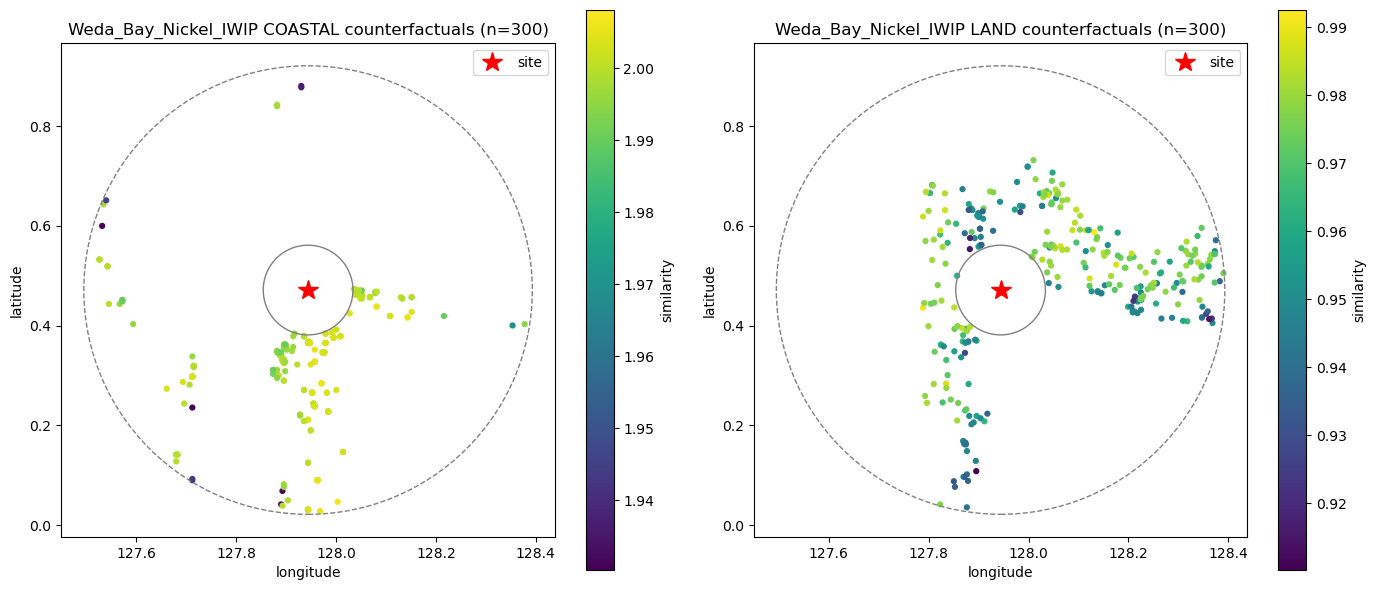

In [45]:
km_to_deg = 1 / 111.32
fig, axes = plt.subplots(1, len(frames), figsize=(7 * len(frames), 6), squeeze=False)
for ax, (kind, df) in zip(axes[0], results.groupby("type")):
    sc = ax.scatter(df.longitude, df.latitude, c=df.similarity, s=12, cmap="viridis")
    ax.plot(SITE_LON, SITE_LAT, "r*", ms=15, label="site")
    for r_km, ls in ((MINE_BUF_M / 1000, "-"), (SEARCH_BUF_M / 1000, "--")):
        ax.add_patch(plt.Circle((SITE_LON, SITE_LAT), r_km * km_to_deg, fill=False, ls=ls, color="grey"))
    ax.set_title(f"{SITE_NAME} {kind} counterfactuals (n={len(df)})")
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_aspect("equal")
    plt.colorbar(sc, ax=ax, label="similarity")
    ax.legend()
plt.tight_layout()
plt.show()

---
## Running your own site

1. In **Section 2**, set `SITE_NAME`, `SITE_LAT`, `SITE_LON`.
2. Make sure your exclusion GeoJSON (default: `data/mine_buffers_10km.geojson`) has the 10 km buffers of *all* mines in your study, with an `IsMine` attribute (1 = mine, 0 = placebo). Only mines are excluded. Or set `EXCLUSION_GEOJSON = None`.
3. Set `USE_DEMO_RESULTS = False`, otherwise section D loads the Weda Bay demo files.
4. Run all cells top to bottom. If a site has no water or no land in its buffer, that pipeline is skipped automatically.
5. Look at the maps in A5 / B5 before exporting: the most common problem is a search area that is too small (tiny island, ecoregion boundary close to the site).